# Step 1 — Video → Frames (OpenCV)

**Goal:** open one dashcam video, understand what a *frame* is, and display one frame inline.

**The idea:** a video is a flip-book of still images called **frames**. OpenCV's `cv2.VideoCapture` opens the file and hands us frames one at a time. Each frame is a NumPy array of shape `(height, width, 3)` with pixel values `0–255` (`uint8`).

⚠️ OpenCV stores colors as **BGR**, not RGB — we convert to RGB before displaying, or the image looks blue-tinted.

Run each cell with **Shift+Enter**.

In [1]:
import cv2
import matplotlib.pyplot as plt

# Pick one dashcam video to look at.
VIDEO_PATH = "../Dataset/videos/test/Accident/000456.mp4"
# NOTE: paths are relative to this notebook (inside learning/), so we go up one
# level with '../' to reach Dataset/.

## 1. Open the video and ask it about itself
`VideoCapture` is the video reader. It streams frames — it does **not** load the whole file into memory.

In [2]:
cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"Could not open video: {VIDEO_PATH}"

fps         = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"frames   : {frame_count}")
print(f"fps      : {fps}")
print(f"size WxH : {width} x {height}")
print(f"duration : {frame_count / fps:.1f} seconds")

frames   : 100
fps      : 25.0
size WxH : 1280 x 720
duration : 4.0 seconds


## 2. Read every frame into a list
`cap.read()` returns `(ok, frame)`. `ok` is `True` while frames remain, `False` at the end.

In [3]:
frames = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)
cap.release()

print(f"frames read : {len(frames)}")
print(f"one frame   : shape={frames[0].shape}  dtype={frames[0].dtype}")
print("   -> (rows, cols, color-channels),  uint8 = pixel values 0-255")

frames read : 100
one frame   : shape=(720, 1280, 3)  dtype=uint8
   -> (rows, cols, color-channels),  uint8 = pixel values 0-255


In [4]:
frames[0].shape

(720, 1280, 3)

In [5]:
type(frames[0])

numpy.ndarray

## 3. Display one frame INLINE
We convert BGR → RGB so matplotlib shows the true colors.

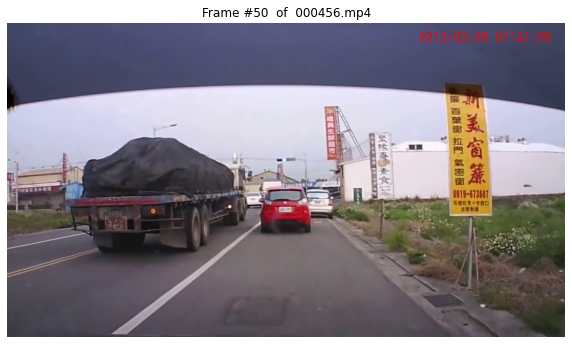

In [6]:
frame_index = 50
one_frame_bgr = frames[frame_index]
one_frame_rgb = cv2.cvtColor(one_frame_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(one_frame_rgb)
plt.title(f"Frame #{frame_index}  of  {VIDEO_PATH.split('/')[-1]}")
plt.axis("off")
plt.show()

## What to take away
1. `VideoCapture` streams frames; loop `cap.read()` until `ok` is `False`.
2. A frame is a NumPy array `(H, W, 3)`, `uint8` — the same array type we saw inside the `.npz`.
3. OpenCV is **BGR**; convert to RGB before displaying (and later before feeding VGG).

**Try it:** change `frame_index` to see a different moment, or change `VIDEO_PATH` to a NonAccident clip.

Next: **Step 2 — detect the objects in this frame.**